# 08 · Peri-Infarct Protein Gradients

**C-Stroke dataset · case HB02CV · H&E infarct annotations combined with IHC annotations**

The tissue response to an ischaemic stroke is organised in space around the infarct. Some processes concentrate in the necrotic core, others in a narrow band at its border, and others extend into the surrounding tissue. The C-Stroke dataset makes this organisation measurable. The infarct is outlined on H&E sections, and seven proteins are annotated on neighbouring immunohistochemistry (IHC) sections, all registered to one coordinate frame per block.

> **Where, relative to the infarct border, does each annotated pathological process concentrate?**

### What the notebook does
1. Pairs every annotated IHC slide with the infarct annotation of the H&E section in the same set.
2. Computes, for every tissue pixel, its signed distance to the infarct border (negative inside, positive outside).
3. Measures, in 0.5 mm distance bands, the share of tissue covered by the protein annotation and the mean DAB optical density.
4. Pools the band profiles over all slides with bootstrap confidence intervals and orders the proteins from core to periphery.
5. Cross-checks the annotation profiles against the annotation-independent DAB signal, and compares blocks.

### Data access
Everything is read from the public C-Stroke deployment at `https://c-stroke.humanbrain.in`: the slide catalogue, the IIPImage server and the annotation API. No credentials or internal services are needed. Downloads are cached under `~/.cache/cstroke`.

### Requirements and runtime
CPU only; runs on Google Colab, Kaggle or a local Jupyter installation. The analysis works on 25 µm per pixel images, so each slide is a single download. The full run over roughly 200 slide pairs takes about 5–10 minutes the first time, and about a minute from cache.

### How to explore
All settings are in the **Configuration** cell (Section 1.2): the proteins, the width and range of the distance bands, the pair selection rules, the worked example, and the protein shown per block in Section 7. Each section ends with suggestions for what to change.

### Contents
1. Setup
2. Pairing IHC slides with infarct annotations
3. A worked example
4. Band profiles for all pairs
5. Protein gradients around the infarct
6. Cross-check with the DAB signal
7. Consistency across blocks
8. Summary and limitations

## 1. Setup

### 1.1 Environment

The analysis uses `slide_utils.py` from the repository root (next to `roi_utils.py`, `annotations_utils.py` and `mri_utils.py`). Outside the repository, for example on Colab, it is downloaded from `SLIDE_UTILS_URL`.

In [1]:
import sys
import urllib.request
from pathlib import Path

SLIDE_UTILS_URL = "https://raw.githubusercontent.com/24f2007780/stroke_utils/main/slide_utils_v1.py"

# Use the repository copy when available (notebooks/ or the repository root), otherwise download it.
repo_root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "slide_utils_v1.py").exists()), None)
if repo_root is None:
    urllib.request.urlretrieve(SLIDE_UTILS_URL, "slide_utils_v1.py")
    repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import warnings
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import ndimage as ndi
from scipy import stats

import slide_utils_v1 as su

su.set_plot_style()
pd.set_option("display.float_format", "{:.3f}".format)
print("slide_utils_v1 loaded from", su.__file__)

slide_utils_v1 loaded from /home/antareep/workspace/stroke_notebook/stroke_utils/slide_utils_v1.py


### 1.2 Configuration

| Parameter | Meaning |
|---|---|
| `PROTEINS` | IHC proteins to analyse. |
| `ANALYSIS_MPP` | Resolution of the analysis grid in µm per pixel. Distances are measured on this grid. |
| `BAND_EDGES_MM` | Edges of the signed distance bands in mm; negative values lie inside the infarct. |
| `MIN_BAND_AREA_MM2` | A slide contributes to a band only when it has at least this much tissue in that band. |
| `MAX_SECTION_GAP_MM` | Maximum distance between an IHC section and the H&E section that supplies its infarct outline. |
| `MIN_INFARCT_AREA_MM2` | Pairs whose infarct annotation is smaller than this are not used. |
| `FAR_FIELD_MM` | Distance range used as the reference level in Sections 5.2 and 6. |
| `MIN_SLIDES_PER_BAND` | Bands reached by fewer slides are not plotted for a protein, because their averages are unstable. |
| `EXAMPLE_SET` | Set used for the worked example in Section 3. |
| `DETAIL_PROTEIN` | Protein shown per block in Section 7. |

In [3]:
PROTEINS = ["FIB", "APP", "CD68", "GAP43", "HIF1a", "GFAP", "CD34"]

# Analysis grid and distance bands
ANALYSIS_MPP = 25.0                                # um/px
BAND_EDGES_MM = np.arange(-4.0, 10.01, 0.5)
MIN_BAND_AREA_MM2 = 0.25

# Pair selection
MAX_SECTION_GAP_MM = 0.5
MIN_INFARCT_AREA_MM2 = 2.0

# Statistics
FAR_FIELD_MM = (6.0, 10.0)
MIN_SLIDES_PER_BAND = 5
N_BOOTSTRAP = 2000
RANDOM_SEED = 7

# Examples
EXAMPLE_SET = 87
DETAIL_PROTEIN = "CD68"

WORKERS = 6                                        # parallel downloads

### 1.3 Analysis functions

* `load_pair` downloads one IHC slide at the analysis resolution. It rasterises the protein annotations of that slide and the infarct annotation of its H&E neighbour onto the same grid, and computes the signed distance to the infarct border.
* `band_profile` summarises one pair per distance band. It records the tissue area, the share of tissue inside any protein annotation (`coverage`), the mean annotation grade and the mean DAB optical density.
* `bootstrap_mean` pools per-slide profiles. Slides are resampled with replacement to give 95% confidence intervals for the mean profile.

In [4]:
DOWNSAMPLE = ANALYSIS_MPP / su.MPP_LEVEL0
BAND_MID = (BAND_EDGES_MM[:-1] + BAND_EDGES_MM[1:]) / 2
PX_AREA_MM2 = (ANALYSIS_MPP / 1000) ** 2


def signed_distance_mm(mask):
    # Euclidean distance to the mask boundary in mm: negative inside the mask, positive outside.
    inside = ndi.distance_transform_edt(mask)
    outside = ndi.distance_transform_edt(~mask)
    return np.where(mask, -inside, outside) * ANALYSIS_MPP / 1000


def load_pair(pair):
    # IHC image, tissue mask, protein grades, infarct mask and signed distance on one grid.
    bbox = su.tissue_bbox(pair.path)
    image, region = su.fetch_region(pair.path, *bbox, downsample=DOWNSAMPLE)
    infarct = su.rasterize_annotations(su.load_annotations(pair.infarct_url), region, value="binary").astype(bool)
    grade = su.rasterize_annotations(su.load_annotations(pair.annotation_url), region)
    _, dab = su.stain_separation(image)
    return {"image": image, "region": region, "tissue": su.tissue_mask(image), "infarct": infarct,
            "grade": grade, "dab": dab, "distance": signed_distance_mm(infarct)}


def band_profile(data):
    # One row per distance band with enough tissue.
    band = np.digitize(data["distance"], BAND_EDGES_MM) - 1
    rows = []
    for k, mid in enumerate(BAND_MID):
        m = data["tissue"] & (band == k)
        area = m.sum() * PX_AREA_MM2
        if area < MIN_BAND_AREA_MM2:
            continue
        rows.append({"band": k, "distance_mm": mid, "tissue_mm2": area,
                     "coverage": float((data["grade"][m] > 0).mean()),
                     "mean_grade": float(data["grade"][m].mean()),
                     "dab": float(data["dab"][m].mean())})
    return pd.DataFrame(rows)


def bootstrap_mean(matrix, n=N_BOOTSTRAP, seed=RANDOM_SEED):
    # matrix: slides x bands (NaN where a slide does not reach a band).
    # Returns the mean profile, its 95% bootstrap interval and the bootstrap replicates.
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(matrix), size=(n, len(matrix)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)       # all-NaN bands are expected and stay NaN
        replicates = np.nanmean(matrix[idx], axis=1)
        mean = np.nanmean(matrix, axis=0)
        low, high = np.nanpercentile(replicates, [2.5, 97.5], axis=0)
    return mean, low, high, replicates


def shade_infarct(ax, label=True):
    # Light background for the inside of the infarct and a line at its border.
    ax.axvspan(BAND_EDGES_MM[0], 0, color="#f0efec", lw=0, zorder=0)
    ax.axvline(0, color="#52514e", lw=1, zorder=1)
    if label:
        ax.text(0.02, 0.97, "inside", transform=ax.transAxes, va="top", fontsize=8.5, color="#52514e")
        ax.text(0.98, 0.97, "outside", transform=ax.transAxes, va="top", ha="right", fontsize=8.5, color="#52514e")

## 2. Pairing IHC slides with infarct annotations

Each set in the catalogue anchors one IHC section and lists its nearest H&E section. When that H&E section carries an *infarcted region* annotation, the IHC slide and the infarct outline form a **pair**. Both live in the same registered coordinate frame, so the infarct polygon can be placed directly on the IHC slide.

Infarct annotations exist for blocks 313, 314 and 315. The H&E section is usually 60 µm from the IHC section, at most a few hundred µm, which is small compared with the millimetre-scale gradients measured here. Pairs further apart than `MAX_SECTION_GAP_MM` are excluded.

In [5]:
catalog = su.load_slide_catalog()
ihc = catalog[(catalog.stain == "IHC") & catalog.annotation_url.notna() & catalog.protein.isin(PROTEINS)]
he = (catalog[(catalog.stain == "HE") & catalog.annotation_url.notna()]
      [["set_id", "section", "annotation_url", "dist_from_anchor_mm"]]
      .rename(columns={"section": "he_section", "annotation_url": "infarct_url",
                       "dist_from_anchor_mm": "section_gap_mm"}))
pairs = ihc.merge(he, on="set_id")
pairs["section_gap_mm"] = pairs.section_gap_mm.abs()


def infarct_area_mm2(url):
    try:
        return sum(a["geometry"].area for a in su.load_annotations(url)) * su.MPP_LEVEL0 ** 2 / 1e6
    except ValueError:
        return np.nan


with ThreadPoolExecutor(max_workers=8) as ex:
    pairs["infarct_mm2"] = list(ex.map(infarct_area_mm2, pairs.infarct_url))

pairs["used"] = (pairs.section_gap_mm <= MAX_SECTION_GAP_MM) & (pairs.infarct_mm2 >= MIN_INFARCT_AREA_MM2)
print(f"{len(pairs)} IHC slides have an infarct-annotated H&E neighbour; {int(pairs.used.sum())} pass the selection")
pairs[["set_id", "protein", "biosample", "section", "he_section", "section_gap_mm", "infarct_mm2", "used"]].head()

209 IHC slides have an infarct-annotated H&E neighbour; 191 pass the selection


,set_id,protein,biosample,section,he_section,section_gap_mm,infarct_mm2,used
0,8,HIF1a,314,1271,1250,0.420,10.358,True
1,9,HIF1a,314,1265,1250,0.300,10.358,True
2,10,FIB,314,1259,1250,0.180,10.358,True
3,11,GFAP,314,1253,1250,0.060,10.358,True
4,12,CD68,314,1247,1250,0.060,10.358,True


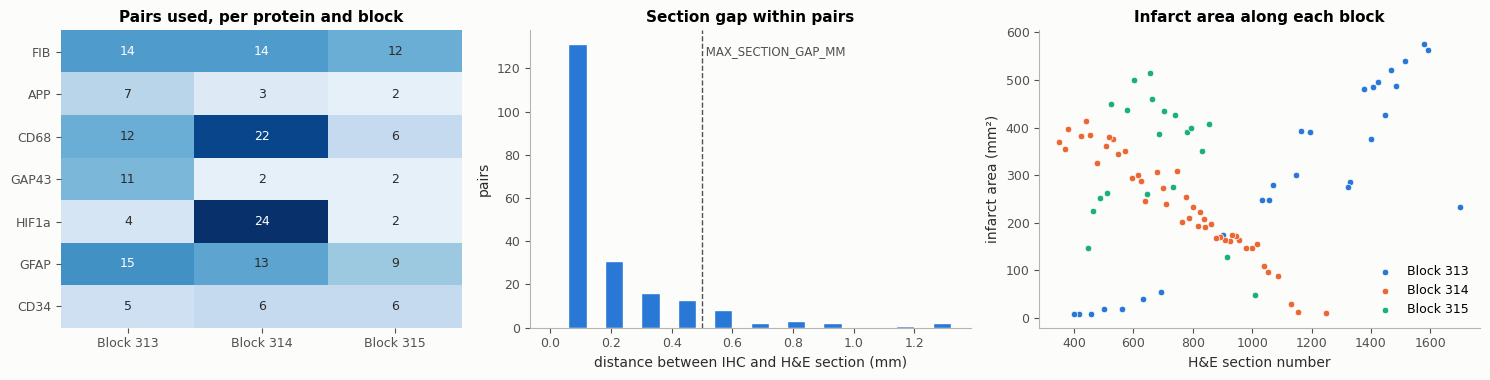

In [6]:
used = pairs[pairs.used].reset_index(drop=True)
counts = used.pivot_table(index="protein", columns="biosample", values="section", aggfunc="count",
                          fill_value=0).reindex(PROTEINS).fillna(0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
ax = axes[0]
ax.imshow(counts.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(counts.shape[1]), [f"Block {b}" for b in counts.columns])
ax.set_yticks(range(counts.shape[0]), counts.index)
for (r, c), v in np.ndenumerate(counts.values):
    ax.text(c, r, v, ha="center", va="center", fontsize=9,
            color="white" if v > counts.values.max() * 0.55 else "#2b2b29")
ax.spines[:].set_visible(False)
ax.set_title("Pairs used, per protein and block")

ax = axes[1]
ax.hist(pairs.section_gap_mm, bins=np.arange(0, pairs.section_gap_mm.max() + 0.1, 0.06), color="#2a78d6",
        edgecolor="#fcfcfb")
ax.axvline(MAX_SECTION_GAP_MM, ls="--", color="#52514e", lw=1)
ax.text(MAX_SECTION_GAP_MM, ax.get_ylim()[1] * 0.95, " MAX_SECTION_GAP_MM", fontsize=8.5, va="top",
        color="#52514e")
ax.set_xlabel("distance between IHC and H&E section (mm)")
ax.set_ylabel("pairs")
ax.set_title("Section gap within pairs")

ax = axes[2]
for b, color in zip(sorted(used.biosample.unique()), ["#2a78d6", "#eb6834", "#1baf7a"]):
    sub = used.drop_duplicates("he_section")[lambda d: d.biosample == b]
    ax.scatter(sub.he_section, sub.infarct_mm2, s=22, color=color, label=f"Block {b}", edgecolor="white", lw=0.5)
ax.set_xlabel("H&E section number")
ax.set_ylabel("infarct area (mm²)")
ax.set_title("Infarct area along each block")
ax.legend()
plt.tight_layout()
plt.show()

## 3. A worked example

Before pooling, here is the full procedure on one pair.

* **Left:** the H&E section with its infarct annotation.
* **Centre:** the paired IHC section with its protein annotations, and the infarct outline transferred from the H&E section.
* **Right:** the signed distance to the infarct border for every tissue pixel. Red is inside the infarct and blue is outside, with contours every 2 mm.

Distances are Euclidean in the section plane: the straight-line distance to the nearest point of the infarct border.

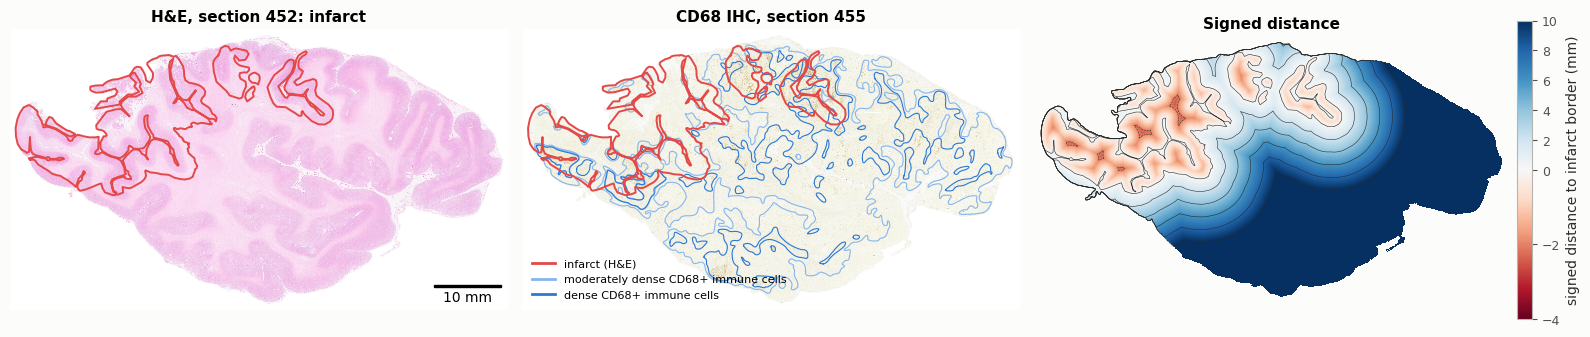

In [7]:
example = used[used.set_id == EXAMPLE_SET]
if example.empty:
    raise ValueError(f"Set {EXAMPLE_SET} has no usable pair; choose one of {sorted(used.set_id.unique())[:20]} ...")
example = example.iloc[0]
data = load_pair(example)
region = data["region"]
example_he = catalog[(catalog.set_id == example.set_id) & (catalog.stain == "HE")].iloc[0]
he_image, _ = su.fetch_region(example_he.path, region.x0, region.y0, region.shape[1] * region.downsample,
                              region.shape[0] * region.downsample, downsample=region.downsample)
infarct_annotations = su.load_annotations(example.infarct_url)
protein_annotations = su.load_annotations(example.annotation_url)
classes = su.annotation_classes(example.protein)
INFARCT_COLOR = "#e34948"

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].imshow(he_image)
su.draw_annotation_outlines(axes[0], infarct_annotations, region, colors={1: INFARCT_COLOR}, linewidth=1.4)
axes[0].set_title(f"H&E, section {example_he.section}: infarct")
axes[1].imshow(data["image"])
su.draw_annotation_outlines(axes[1], protein_annotations, region, linewidth=0.8)
su.draw_annotation_outlines(axes[1], infarct_annotations, region, colors={1: INFARCT_COLOR}, linewidth=1.4)
axes[1].set_title(f"{example.protein} IHC, section {example.section}")
axes[1].legend(handles=[Line2D([], [], color=INFARCT_COLOR, lw=2, label="infarct (H&E)")]
               + [Line2D([], [], color=su.GRADE_COLORS[g], lw=2, label=classes[g]) for g in range(1, len(classes))],
               loc="lower left", fontsize=8)
dist = np.where(data["tissue"], data["distance"], np.nan)
h = axes[2].imshow(dist, cmap="RdBu", norm=TwoSlopeNorm(vmin=BAND_EDGES_MM[0], vcenter=0, vmax=BAND_EDGES_MM[-1]))
axes[2].contour(np.nan_to_num(dist, nan=99), levels=np.arange(-4, 10.1, 2), colors="#2b2b29", linewidths=0.4)
plt.colorbar(h, ax=axes[2], fraction=0.03, pad=0.02, label="signed distance to infarct border (mm)")
axes[2].set_title("Signed distance")
for ax in axes:
    ax.axis("off")
su.scale_bar(axes[0], region, 10)
plt.tight_layout()
plt.show()

The distance map is cut into bands of 0.5 mm. Within each band, the **coverage** is the share of tissue that lies inside any protein annotation. Plotted against distance, the coverage gives this slide's profile.

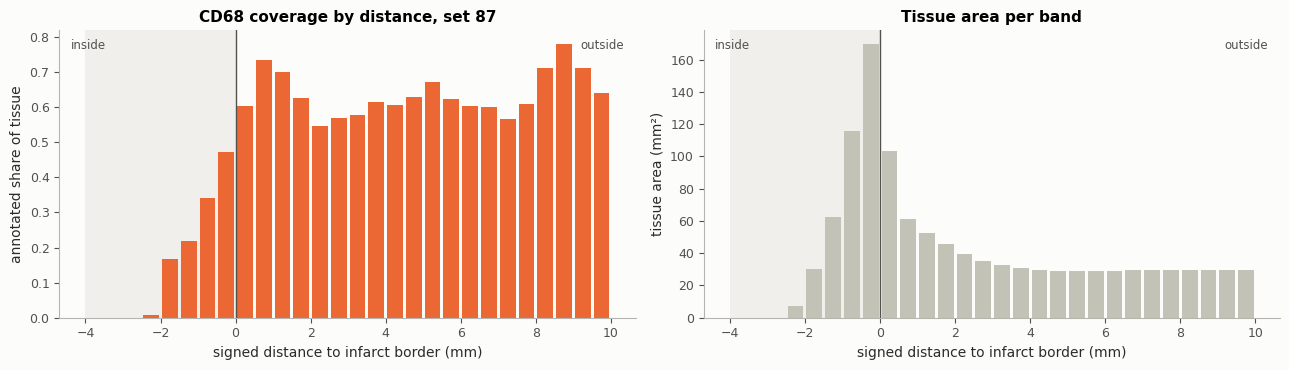

In [8]:
example_profile = band_profile(data)
color = su.PROTEIN_COLORS.get(example.protein, "#2a78d6")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.bar(example_profile.distance_mm, example_profile.coverage, width=0.42, color=color)
shade_infarct(ax1)
ax1.set_xlabel("signed distance to infarct border (mm)")
ax1.set_ylabel("annotated share of tissue")
ax1.set_title(f"{example.protein} coverage by distance, set {example.set_id}")
ax2.bar(example_profile.distance_mm, example_profile.tissue_mm2, width=0.42, color="#c3c2b7")
shade_infarct(ax2)
ax2.set_xlabel("signed distance to infarct border (mm)")
ax2.set_ylabel("tissue area (mm²)")
ax2.set_title("Tissue area per band")
plt.tight_layout()
plt.show()

The tissue area per band (right) is a reminder that bands deep inside the infarct contain little tissue on most slides. Only large infarcts reach −3 or −4 mm, so the deep-core estimates rest on fewer slides. Section 5 shows how many slides contribute to each band, and bands with fewer than `MIN_SLIDES_PER_BAND` slides are left out.

*To explore:* set `EXAMPLE_SET` to another set listed in `used.set_id`, for example one with a GFAP or FIB slide, and compare the shape of its profile.

## 4. Band profiles for all pairs

The same procedure runs on every used pair in parallel. Only the band summaries are kept, so memory use stays small. Pairs whose image or annotation file is unavailable on the server are reported and skipped.

In [9]:
def process(pair):
    try:
        profile = band_profile(load_pair(pair))
    except (ValueError, RuntimeError) as err:
        return None, f"set {pair.set_id} ({pair.protein} {pair.biosample}/{pair.section}): {str(err).splitlines()[0]}"
    for column in ("set_id", "protein", "biosample", "section"):
        profile[column] = pair[column]
    return profile, None


with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    results = list(ex.map(process, [row for _, row in used.iterrows()]))

profiles = pd.concat([p for p, _ in results if p is not None], ignore_index=True)
failures = [msg for _, msg in results if msg]
print(f"{profiles.set_id.nunique()} pairs profiled, {len(profiles)} band rows")
if failures:
    print("Skipped:", *failures, sep="\n  ")
profiles.head()

191 pairs profiled, 4927 band rows


,band,distance_mm,tissue_mm2,coverage,mean_grade,dab,set_id,protein,biosample,section
0,6,-0.750,2.590,0.000,0.000,0.008,8,HIF1a,314,1271
1,7,-0.250,6.337,0.000,0.000,0.009,8,HIF1a,314,1271
2,8,0.250,9.912,0.012,0.012,0.011,8,HIF1a,314,1271
3,9,0.750,11.891,0.045,0.045,0.012,8,HIF1a,314,1271
4,10,1.250,13.656,0.022,0.022,0.012,8,HIF1a,314,1271


## 5. Protein gradients around the infarct

### 5.1 Coverage profiles

One panel per protein. Thin lines are individual slides, the thick line is the mean over slides, and the band around it is the 95% bootstrap confidence interval obtained by resampling slides. The grey background marks the inside of the infarct. The last panel shows how many slides reach each band.

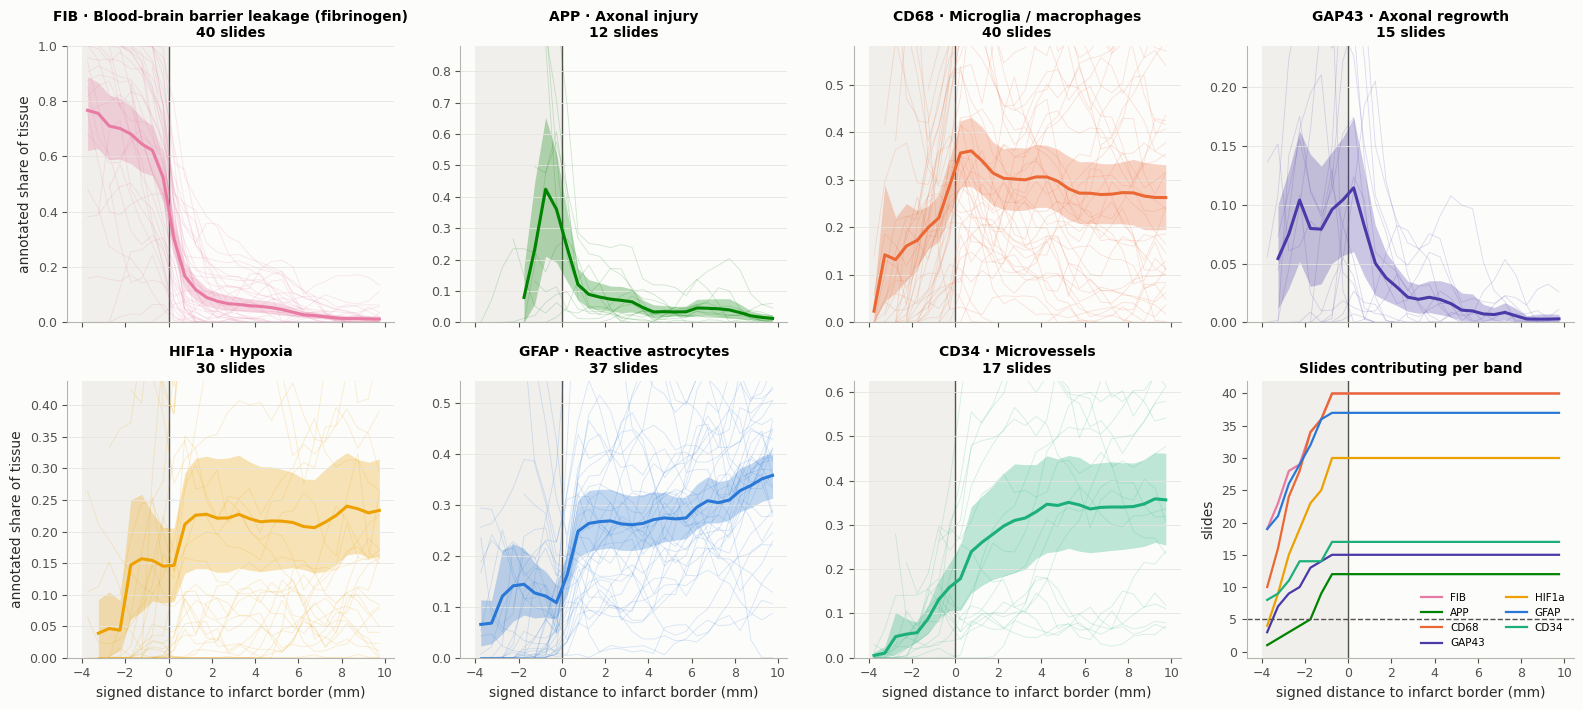

In [10]:
def profile_matrix(df, protein, column):
    # Slides x bands matrix of one measure for one protein (NaN where a slide does not reach a band).
    sub = df[df.protein == protein]
    m = sub.pivot_table(index=["set_id", "section"], columns="band", values=column)
    return m.reindex(columns=range(len(BAND_MID))).to_numpy()


summary = {}
for protein in PROTEINS:
    m = profile_matrix(profiles, protein, "coverage")
    if len(m) == 0:
        continue
    mean, low, high, reps = bootstrap_mean(m)
    n = np.sum(~np.isnan(m), axis=0)
    valid = n >= MIN_SLIDES_PER_BAND
    summary[protein] = {"matrix": m, "mean": np.where(valid, mean, np.nan), "low": np.where(valid, low, np.nan),
                        "high": np.where(valid, high, np.nan), "replicates": reps[:, valid], "valid": valid, "n": n}

n_cols = 4
n_rows = int(np.ceil((len(summary) + 1) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.6 * n_rows), sharex=True)
axes = axes.ravel()
for ax, (protein, s) in zip(axes, summary.items()):
    color = su.PROTEIN_COLORS.get(protein, "#2a78d6")
    shade_infarct(ax, label=False)
    for row in s["matrix"]:
        ax.plot(BAND_MID, row, color=color, lw=0.6, alpha=0.18)
    ax.fill_between(BAND_MID, s["low"], s["high"], color=color, alpha=0.28, lw=0)
    ax.plot(BAND_MID, s["mean"], color=color, lw=2.2)
    top = np.nanmax(s["high"])
    ax.set_ylim(0, min(1.0, top * 1.35) if np.isfinite(top) else 1)
    ax.set_title(f"{protein} · {su.PROTEIN_INFO[protein]['marker']}\n{len(s['matrix'])} slides", fontsize=10)
    ax.grid(axis="y")
for ax in axes[::n_cols]:
    ax.set_ylabel("annotated share of tissue")
ax = axes[len(summary)]
for protein, s in summary.items():
    ax.plot(BAND_MID, s["n"], color=su.PROTEIN_COLORS.get(protein, "#52514e"), lw=1.6, label=protein)
ax.axhline(MIN_SLIDES_PER_BAND, ls="--", color="#52514e", lw=1)
shade_infarct(ax, label=False)
ax.set_title("Slides contributing per band", fontsize=10)
ax.set_ylabel("slides")
ax.legend(fontsize=7.5, ncol=2)
for ax in axes[len(summary) + 1:]:
    ax.axis("off")
for ax in axes[-n_cols:]:
    ax.set_xlabel("signed distance to infarct border (mm)")
plt.tight_layout()
plt.show()

### 5.2 Enrichment relative to distant tissue

Absolute coverage differs a lot between proteins, because each protein has its own baseline in distant tissue. To compare the *shape* of the gradients, each mean profile is divided by the protein's mean coverage in the far field (`FAR_FIELD_MM`) and shown on a log₂ scale. Red bands are enriched relative to distant tissue and blue bands are depleted. Rows are ordered by the location of the peak (Section 5.3), from core to periphery. Grey cells are bands reached by too few slides.

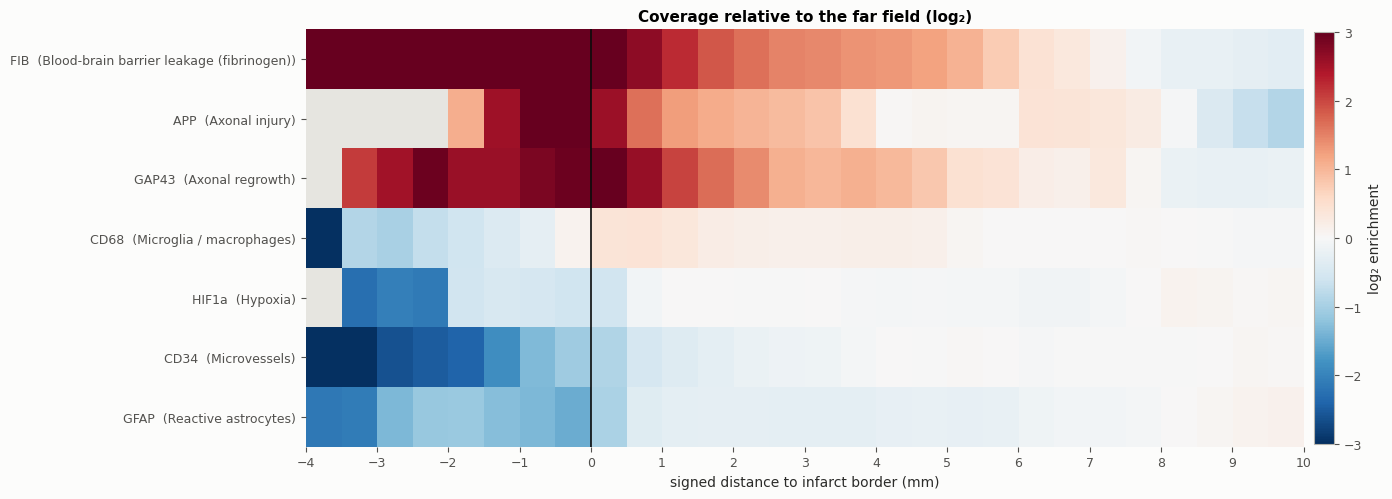

In [11]:
far = (BAND_MID >= FAR_FIELD_MM[0]) & (BAND_MID <= FAR_FIELD_MM[1])
EPS = 0.01                                           # floor that keeps ratios finite for near-zero baselines


def peak_distance(mean_profile):
    return BAND_MID[np.nanargmax(mean_profile)]


peaks = {}
for protein, s in summary.items():
    valid_mid = BAND_MID[s["valid"]]
    boot_peaks = valid_mid[np.nanargmax(s["replicates"], axis=1)]
    peaks[protein] = {"peak_mm": peak_distance(s["mean"]),
                      "low": np.percentile(boot_peaks, 2.5), "high": np.percentile(boot_peaks, 97.5),
                      "far_field": np.nanmean(s["mean"][far])}
order = sorted(peaks, key=lambda p: peaks[p]["peak_mm"])

enrichment = np.array([np.log2((summary[p]["mean"] + EPS) / (peaks[p]["far_field"] + EPS)) for p in order])
fig, ax = plt.subplots(figsize=(14, 0.5 * len(order) + 1.6))
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#e6e5e0")
h = ax.imshow(np.ma.masked_invalid(enrichment), cmap=cmap, vmin=-3, vmax=3, aspect="auto",
              extent=(BAND_EDGES_MM[0], BAND_EDGES_MM[-1], len(order) - 0.5, -0.5))
ax.axvline(0, color="#0b0b0b", lw=1.2)
ax.set_yticks(range(len(order)), [f"{p}  ({su.PROTEIN_INFO[p]['marker']})" for p in order])
ax.set_xticks(np.arange(BAND_EDGES_MM[0], BAND_EDGES_MM[-1] + 0.1, 1))
ax.set_xlabel("signed distance to infarct border (mm)")
ax.set_title("Coverage relative to the far field (log₂)")
plt.colorbar(h, ax=ax, fraction=0.02, pad=0.01, label="log₂ enrichment")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### 5.3 Where each process peaks

The peak is the distance band with the highest mean coverage. Its uncertainty comes from the same bootstrap: the peak is recomputed on every resampled set of slides, and the bars span the central 95% of those peaks. A wide interval means the profile is flat or has more than one maximum.

The table below summarises coverage in four zones: the **core** (deeper than 1 mm inside), the **border** (within 1 mm of the boundary on either side), the **near field** (1–3 mm outside) and the **far field**.

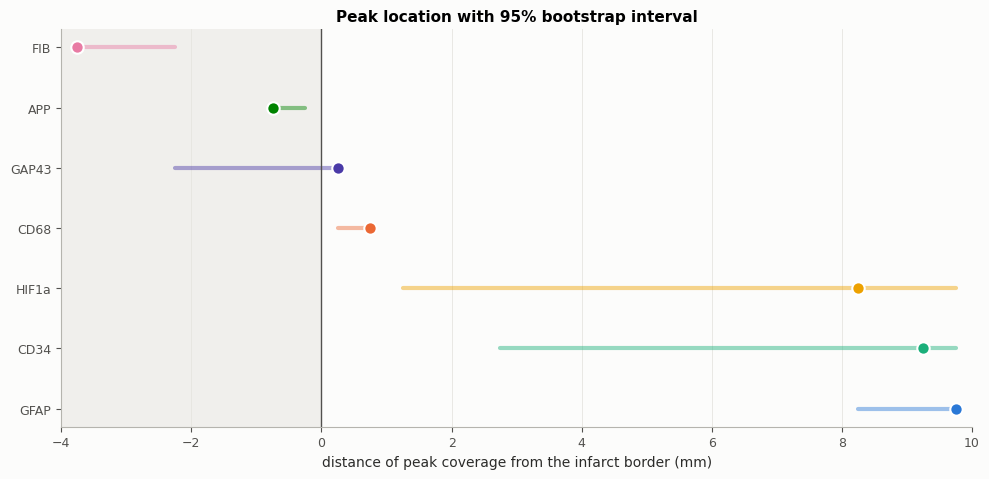

,core (< -1 mm),border (-1 to +1 mm),near field (+1 to +3 mm),far field,peak (mm),slides
FIB,0.709,0.403,0.088,0.017,-3.750,40
APP,0.157,0.285,0.078,0.032,-0.750,12
GAP43,0.078,0.099,0.035,0.005,0.250,15
CD68,0.139,0.307,0.315,0.269,0.750,40
HIF1a,0.087,0.164,0.224,0.224,8.250,30
CD34,0.044,0.177,0.287,0.345,9.250,17
GFAP,0.111,0.160,0.265,0.324,9.750,37


In [12]:
fig, ax = plt.subplots(figsize=(10, 0.5 * len(order) + 1.4))
for y, protein in enumerate(order):
    p = peaks[protein]
    color = su.PROTEIN_COLORS.get(protein, "#52514e")
    ax.plot([p["low"], p["high"]], [y, y], color=color, lw=3, alpha=0.45, solid_capstyle="round")
    ax.scatter(p["peak_mm"], y, s=80, color=color, edgecolor="white", lw=1.5, zorder=3)
ax.axvspan(BAND_EDGES_MM[0], 0, color="#f0efec", lw=0, zorder=0)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(BAND_EDGES_MM[0], BAND_EDGES_MM[-1])
ax.set_xlabel("distance of peak coverage from the infarct border (mm)")
ax.set_title("Peak location with 95% bootstrap interval")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

zones = {"core (< -1 mm)": BAND_MID < -1, "border (-1 to +1 mm)": np.abs(BAND_MID) <= 1,
         "near field (+1 to +3 mm)": (BAND_MID > 1) & (BAND_MID <= 3), "far field": far}
zone_table = pd.DataFrame({z: [np.nanmean(summary[p]["mean"][m]) for p in order] for z, m in zones.items()},
                          index=order)
zone_table["peak (mm)"] = [peaks[p]["peak_mm"] for p in order]
zone_table["slides"] = [len(summary[p]["matrix"]) for p in order]
zone_table

**Reading the gradients.** With the default settings (191 slide pairs), the proteins fall into three spatial patterns.

1. **Concentrated in the core: fibrinogen.** About 70–80% of the tissue deep inside the infarct is annotated, falling steeply across the border to a few per cent within 2 mm. This fits breakdown of the blood–brain barrier in infarcted tissue, with plasma fibrinogen leaking into the parenchyma.
2. **Peaked at the border: APP, GAP43 and CD68.** Axonal injury (APP) peaks just *inside* the border, at about −0.75 mm with a tight interval. GAP43, a marker of axonal regrowth, peaks at the border. Relative to distant tissue, both are enriched more than eight-fold near the boundary. CD68 peaks just *outside* the border, at about +0.75 mm, but its enrichment is modest because CD68-positive microglia are annotated widely across the section.
3. **Depleted in the core, rising outside: GFAP, CD34 and HIF1a.** Coverage is low inside the infarct and rises outside it: steeply within the first millimetre, then more gradually (CD34 over about 4 mm, GFAP throughout the analysed range). Their "peaks" lie at the outer edge of the analysed range with wide intervals, which means there is no peri-infarct maximum. Low GFAP and CD34 coverage inside the infarct is consistent with the loss of astrocytes and of the microvascular network in necrotic tissue.

One observation deserves a closer look on the slides themselves. At a subacute stage, macrophages would be expected to fill the necrotic core, yet CD68 coverage is lowest deep inside the infarct outline. Possible reasons are the 60 µm or more between the H&E section that defines the infarct and the IHC section, and annotation practice inside necrotic tissue.

## 6. Cross-check with the DAB signal

The profiles above are built from expert annotations. An independent check uses the stain itself: the mean DAB optical density in each band, measured on the same IHC slides. Staining intensity differs between slides, so each slide's DAB profile is first divided by its own far-field level. Annotation coverage cannot be normalised per slide in the same way, because many slides have no annotation in the far field.

The two measures have different units, so both mean profiles are rescaled to the range 0–1 to compare their **shapes**. The panel title gives the rank correlation between the two shapes across bands. Notebook `ihc_stain_quantification_vs_annotations.ipynb` showed that DAB tracks the annotation closely for some proteins and poorly for others, so agreement is expected to vary in the same way.

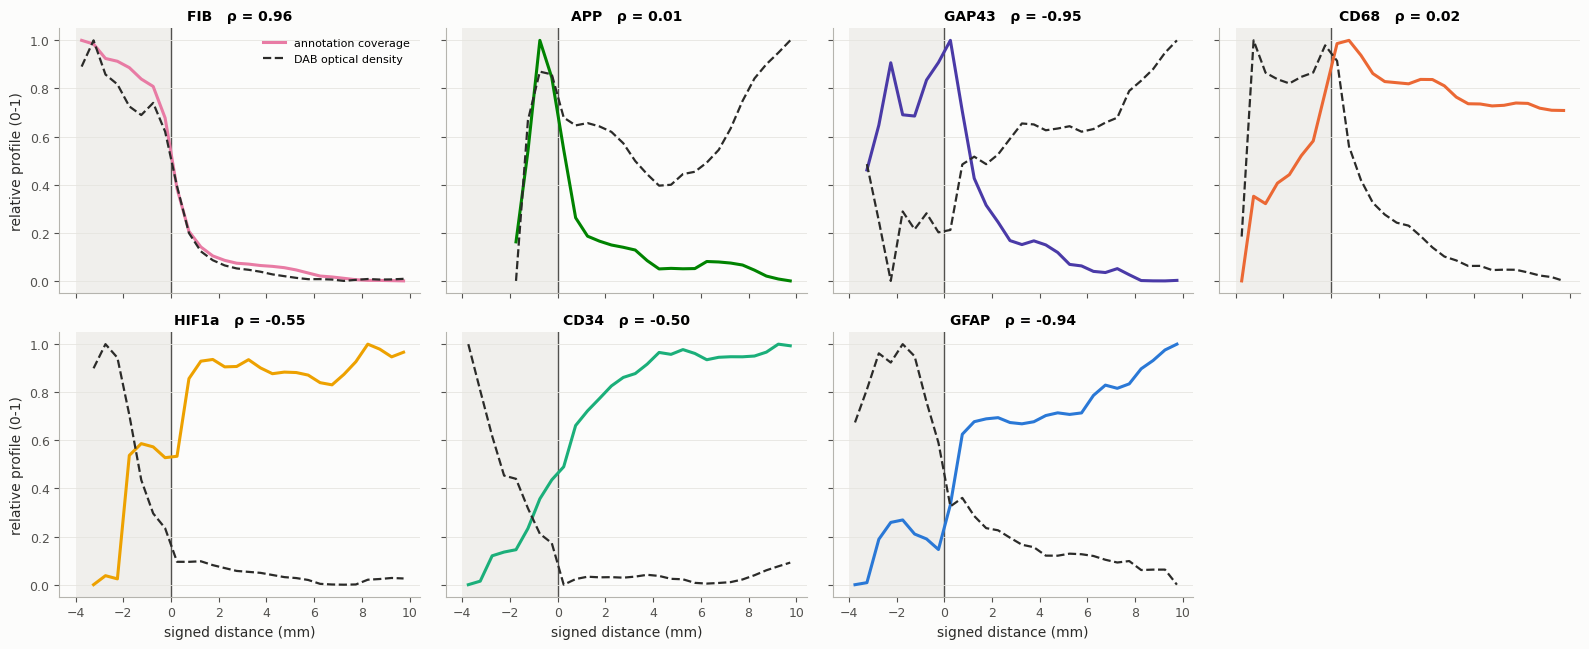

In [13]:
def rescale(v):
    lo, hi = np.nanmin(v), np.nanmax(v)
    return (v - lo) / (hi - lo) if hi > lo else v * 0


fig, axes = plt.subplots(2, 4, figsize=(16, 6.6), sharex=True, sharey=True)
axes = axes.ravel()
dab_agreement = {}
for ax, protein in zip(axes, order):
    s = summary[protein]
    dab = profile_matrix(profiles, protein, "dab")
    with np.errstate(all="ignore"):
        dab_rel = dab / np.nanmean(np.where(far, dab, np.nan), axis=1, keepdims=True)
    dab_mean = np.where(s["valid"], np.nanmean(dab_rel, axis=0), np.nan)
    ok = s["valid"] & np.isfinite(dab_mean)
    rho = stats.spearmanr(s["mean"][ok], dab_mean[ok])[0]
    dab_agreement[protein] = rho
    color = su.PROTEIN_COLORS.get(protein, "#2a78d6")
    shade_infarct(ax, label=False)
    ax.plot(BAND_MID, rescale(s["mean"]), color=color, lw=2.2, label="annotation coverage")
    ax.plot(BAND_MID, rescale(dab_mean), color="#2b2b29", lw=1.6, ls="--", label="DAB optical density")
    ax.set_title(f"{protein}   ρ = {rho:.2f}", fontsize=10)
    ax.grid(axis="y")
for ax in axes[len(order):]:
    ax.axis("off")
axes[0].legend(loc="upper right", fontsize=8)
for ax in axes[::4]:
    ax.set_ylabel("relative profile (0-1)")
for ax in axes[-4:]:
    ax.set_xlabel("signed distance (mm)")
plt.tight_layout()
plt.show()

**Reading the cross-check.** Only **fibrinogen** shows the same shape in both measures (ρ ≈ 0.96). For CD68, GFAP, CD34 and HIF1a, the DAB optical density is *highest inside the infarct*, exactly where their annotation coverage is lowest, so the shapes are unrelated or opposite. For APP and GAP43, whose annotations are small foci, the band-averaged DAB signal is dominated by background staining and does not follow the annotation.

A DAB increase inside necrotic tissue that appears for four different target proteins cannot reflect any one of them. More likely causes are non-specific chromogen deposition in damaged tissue, endogenous pigment, or altered tissue optics. Note also that DAB is measured here at 25 µm per pixel, which averages cells and background. The result agrees with `ihc_stain_quantification_vs_annotations.ipynb`, where the strongest *unannotated* DAB signal on the GFAP example slide lay in and around the infarct.

The practical consequence: in and around an infarct, raw DAB intensity is not a reliable readout of protein expression. Expert annotation, or a model that recognises cell morphology, is needed there.

## 7. Consistency across blocks

A gradient that appears in only one block could reflect that block's anatomy or processing rather than the biology of the lesion. The figure below splits the coverage profile of `DETAIL_PROTEIN` by block. Bands are plotted when at least three slides of that block reach them.

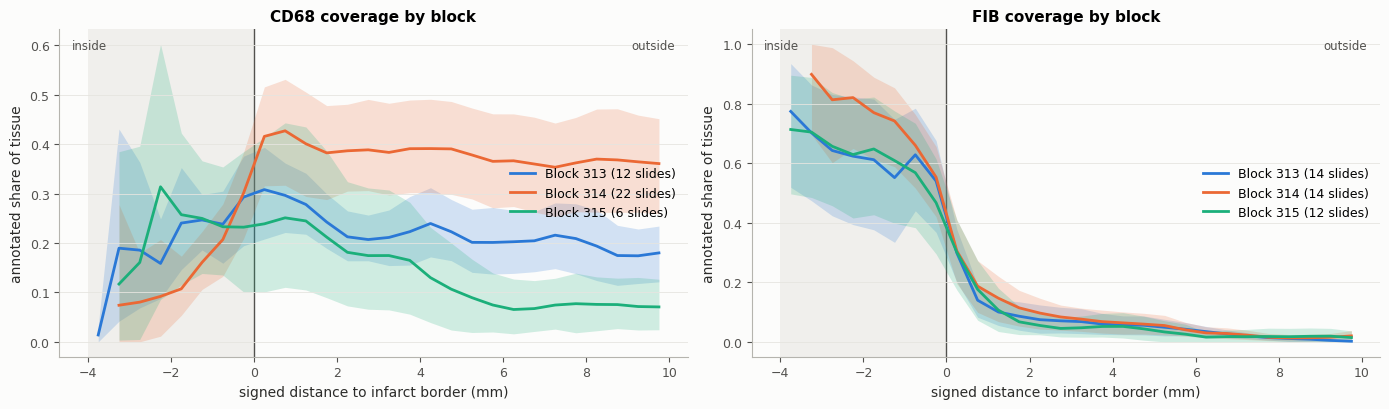

In [14]:
BLOCK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=False)
for ax, protein in zip(axes, [DETAIL_PROTEIN, order[0] if order[0] != DETAIL_PROTEIN else order[-1]]):
    shade_infarct(ax)
    for b, color in zip(sorted(profiles.biosample.unique()), BLOCK_COLORS):
        sub = profiles[(profiles.protein == protein) & (profiles.biosample == b)]
        if sub.set_id.nunique() < 3:
            continue
        m = profile_matrix(sub, protein, "coverage")
        mean, low, high, _ = bootstrap_mean(m, n=500)
        keep = np.sum(~np.isnan(m), axis=0) >= 3
        ax.fill_between(BAND_MID, np.where(keep, low, np.nan), np.where(keep, high, np.nan), color=color,
                        alpha=0.2, lw=0)
        ax.plot(BAND_MID, np.where(keep, mean, np.nan), color=color, lw=2, label=f"Block {b} ({len(m)} slides)")
    ax.set_title(f"{protein} coverage by block")
    ax.set_xlabel("signed distance to infarct border (mm)")
    ax.set_ylabel("annotated share of tissue")
    ax.legend(loc="center right")
    ax.grid(axis="y")
plt.tight_layout()
plt.show()

*To explore:* set `DETAIL_PROTEIN` to any protein in `PROTEINS`. The right panel always shows a second protein for comparison: the one whose peak lies closest to the core.

## 8. Summary and limitations

### Findings
* Registered H&E infarct outlines and IHC annotations together give distance-resolved profiles for seven proteins over about 190 slide pairs from three blocks.
* The annotated processes are ordered in space. Fibrinogen leakage fills the core. Axonal injury (APP) and regrowth (GAP43) peak at the border, with CD68 just outside it. GFAP, CD34 and HIF1a are depleted inside the infarct and rise outside it.
* The core-to-border fibrinogen gradient is reproduced almost identically in all three blocks. CD68 keeps the same shape but its overall level differs between blocks.
* Raw DAB intensity agrees with the annotations only for fibrinogen. For CD68, GFAP, CD34 and HIF1a it rises inside the infarct whatever the target, which argues against reading DAB intensity in necrotic tissue as protein expression.

### Limitations
* **Two-dimensional distances.** Distances are measured within each section plane. The true three-dimensional distance to the infarct surface can be shorter where the border runs obliquely to the cutting plane.
* **Infarct from a neighbouring section.** The infarct outline comes from an H&E section usually 60 µm (at most `MAX_SECTION_GAP_MM`) from the IHC section, so the border position carries an uncertainty of the same order.
* **Euclidean, not tissue-path, distance.** Distances can cross sulci or tissue gaps.
* **Annotation completeness.** Coverage measures where annotators marked pathology. Unmarked tissue is not necessarily free of it.
* **Slides are not independent.** Neighbouring sections of the same block are correlated, so the bootstrap intervals, which resample slides, are optimistic. A single case (HB02CV) is analysed.
* **Pixel size.** Physical distances assume about 0.5 µm per full-resolution pixel, estimated because the scanner calibration is not published.

### Things to try
* Narrow the bands (`BAND_EDGES_MM = np.arange(-2, 4.01, 0.25)`) to resolve the border peaks more finely.
* Use `mean_grade` instead of `coverage` in `profile_matrix` to see whether the *dense* classes sit closer to the border than the *sparse* ones.
* Set `MAX_SECTION_GAP_MM = 0.1` to keep only the closest H&E–IHC pairs and check whether the border peaks sharpen.
* Compare with the MRI view of the same lesion: `mri_utils.lesion_border_profile` computes the analogous profile for diffusion MRI intensities.